# UTS Graf Sains Data

In [ ]:
# !pip install numpy pandas scipy scikit-learn matplotlib networkx tqdm neo4j ipython


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\laragon\bin\python\python-3.13\python.exe -m pip install --upgrade pip


In [2]:
import os, math, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import networkx as nx
from tqdm.auto import tqdm
from neo4j import GraphDatabase
from IPython.display import display, Markdown

c:\Users\rizki\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Konfigurasi ke Neo4j


In [ ]:
url  = "neo4j://127.0.0.1:7687"                                         
auth = (os.getenv("neo4j_user", "neo4j"), os.getenv("neo4j_pw", "password"))  
uts   = os.getenv("NEO4J_DB", "uts")                                     

source = "retailrocket"    
out_dir    = "output"
os.makedirs(out_dir, exist_ok=True)

seed = 42                                       
p1_start, p1_end = "2015-06-04", "2015-08-23"    
p2_start, p2_end = "2015-08-24", "2015-09-13" 

k_neighbors  = 5    
n_rec, n_ads = 5, 3 
min_p1_items = 2   
relevan_events = {"view", "addtocart", "transaction"}

driver = GraphDatabase.driver(url, auth=auth)
try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")
except Exception as e:
    print(type(e).__name__, e)

def write_tx(session, fn, *args):
    runner = getattr(session, "execute_write", None) or session.write_transaction
    return runner(fn, *args)

def run_query(q, **params):
    with driver.session(database=uts) as session:
        return session.run(q, **params).data()

Koneksi Neo4j berhasil!


# 2.1 Wrangling dan EDA 

## No. 1: Menentukan kombinasi periode

* P1 (training): **4 Juni 2015–23 Agustus 2015**.
* P2 (testing): **24 Agustus 2015–13 September 2015**.

Filter menggunakan timestamp dalam UTC dan mencakup seluruh hari pada tanggal akhir masing-masing periode.

In [25]:
events_path = os.path.join(source, "events.csv")
if not os.path.exists(events_path):
    raise FileNotFoundError(f"File '{events_path}' tidak ditemukan!")

events = pd.read_csv(events_path, dtype={"visitorid": str, "itemid": str,
                                         "event": str, "transactionid": "string"})
required = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
assert required <= set(events.columns), f"Kolom hilang: {required - set(events.columns)}"

events["dt"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print("Total baris events.csv :", f"{len(events):,}")
print("Rentang data           :", events["dt"].min(), "->", events["dt"].max())

Total baris events.csv : 2,756,101
Rentang data           : 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00


In [26]:
def filter_period(df, start, end):
    s = pd.Timestamp(start, tz="UTC")
    e = pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)
    return df[(df["dt"] >= s) & (df["dt"] < e)].reset_index(drop=True)

assert p1_end < p2_start, "P1 harus berakhir sebelum P2 dimulai."
p1_dt = filter_period(events, p1_start, p1_end)
p2_dt = filter_period(events, p2_start, p2_end)
assert len(p1_dt) > 0 and len(p2_dt) > 0, "Periode kosong: sesuaikan dengan rentang data di atas."

validasi = pd.DataFrame({
    "periode diminta": [f"{p1_start} s.d. {p1_end}", f"{p2_start} s.d. {p2_end}"],
    "waktu paling awal": [p1_dt["dt"].min(), p2_dt["dt"].min()],
    "waktu paling akhir": [p1_dt["dt"].max(), p2_dt["dt"].max()],
    "jumlah baris": [len(p1_dt), len(p2_dt)],
}, index=["P1 (training)", "P2 (testing)"])
display(validasi)
print("P1 selesai sebelum P2 mulai:", p1_dt["dt"].max() < p2_dt["dt"].min())

,periode diminta,waktu paling awal,waktu paling akhir,jumlah baris
P1 (training),2015-06-04 s.d. 2015-08-23,2015-06-04 00:00:00.993000+00:00,2015-08-23 23:59:56.475000+00:00,1645611
P2 (testing),2015-08-24 s.d. 2015-09-13,2015-08-24 00:00:12.490000+00:00,2015-09-13 23:59:56.743000+00:00,385656


P1 selesai sebelum P2 mulai: True


## No. 2: Simpan hasil filter ke CSV

Data yang telah difilter disimpan menjadi file csv lalu diimpor ke database uts di neo4j desktop

In [27]:
p1 = p1_dt.drop(columns="dt")
p2 = p2_dt.drop(columns="dt")

P1_CSV = os.path.join(out_dir, "events_p1_train.csv")
P2_CSV = os.path.join(out_dir, "events_p2_test.csv")
p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)
print("Tersimpan:", P1_CSV, "|", P2_CSV)

ringkas = pd.DataFrame({
    "periode": [f"{p1_start} s.d. {p1_end}", f"{p2_start} s.d. {p2_end}"],
    "baris": [len(p1), len(p2)],
    "user unik": [p1["visitorid"].nunique(), p2["visitorid"].nunique()],
    "item unik": [p1["itemid"].nunique(), p2["itemid"].nunique()],
    "view": [(p1.event == "view").sum(), (p2.event == "view").sum()],
    "addtocart": [(p1.event == "addtocart").sum(), (p2.event == "addtocart").sum()],
    "transaction": [(p1.event == "transaction").sum(), (p2.event == "transaction").sum()],
}, index=["P1 (training)", "P2 (testing)"])
ringkas

Tersimpan: output\events_p1_train.csv | output\events_p2_test.csv


,periode,baris,user unik,item unik,view,addtocart,transaction
P1 (training),2015-06-04 s.d. 2015-08-23,1645611,858124,189066,1590454,41599,13558
P2 (testing),2015-08-24 s.d. 2015-09-13,385656,218615,94183,372442,10045,3169


Setiap baris interaksi P1 diimpor sebagai satu relasi. Tabel di atas menunjukkan jumlah baris, user unik, item unik, serta komposisi view, addtocart, dan transaction untuk masing-masing periode.

Data yang diimport ke Neo4j hanya data P1 karena model rekomendasi dibangun berdasarkan data histori (P1). P2 hanya disimpan terpisah sebagai file csv dan hanya dipakai sebagai ground truth, yaitu daftar item yang benar-benar diakses user setelah periode P1.

In [29]:
CLEAR_db = True    
if CLEAR_db:
    run_query("MATCH (n) DETACH DELETE n")
    print("Graf dikosongkan.")

def create_constraints(session):
    for q in [
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (u:User) REQUIRE u.visitorId IS UNIQUE",
        "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
    ]:
        session.run(q).consume()

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (u:User {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (u)-[:VIEWED {timestamp: row.timestamp}]->(i))

    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (u)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))

    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (u)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i))
    """
    tx.run(cypher_query, batch=batch).consume()

Graf dikosongkan.


Pada bagian ini, dibuat dua jenis simpul, yaitu User (menggunakan properti visitorId) dan Item (menggunakan properti itemId). 

* `UNWIND` digunakan untuk membaca kumpulan data batch menjadi row (baris)
* `MERGE` digunakan untuk menggabungkan simpul dengan properti yang sama, misal user dengan user, ataupun item dengan item
* `FOREACH (_ IN CASE WHEN row.event = '...' THEN [1] ELSE [] END | CREATE (u)-[:... {timestamp: row.timestamp}]->(i))`, pada cypher ini digunakan untuk membuat relasi dari user ke item, relasi tersebut menyimpan waktu interaksi dalam properti timestamp. Terdapat tiga relasi yang dibuat dalam graf ini, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT.

Setelah itu, data dikirim ke Neo4j

In [30]:
batch = 1000
total_chunks = math.ceil(len(p1) / batch)

with driver.session(database=uts) as session:
    create_constraints(session)
    print(f"Membaca {P1_CSV} ...")
    chunks = pd.read_csv(P1_CSV, chunksize=batch,
                         dtype={"visitorid": str, "itemid": str,
                                "event": str, "transactionid": str})
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor batch"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.astype(object).to_dict(orient="records")
        write_tx(session, import_batch, records)
print("Proses impor selesai.")

Membaca output\events_p1_train.csv ...


Mengimpor batch: 100%|██████████| 1646/1646 [02:57<00:00,  9.27it/s]

Proses impor selesai.


## No. 3: Komposisi subgraph 

Cypher yang digunakan:
* `MATCH (n) RETURN labels(n)[0], count(n)`digunakan untuk mencocokkan semua node, mengambil label pertamanya sebagai jenis simpul (User atau Item), lalu menghitung jumlah per jenis. Pengelompokan dilakukan otomatis oleh `RETURN` karena ada fungsi agregat `count`.
* `MATCH ()-[r]->() RETURN type(r), count(r)`digunakan mencocokkan semua relasi, dikelompokkan menurut tipenya.
* `ORDER BY jumlah DESC`digunakan untuk mengurutkan dari yang terbanyak.

In [31]:
q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
komposisi_simpul = pd.DataFrame(run_query(q_nodes))
rel_counts_before = pd.DataFrame(run_query(q_rels))
display(komposisi_simpul)
display(rel_counts_before)

n_rel = int(rel_counts_before["jumlah"].sum())
print(f"Total relasi di graf: {n_rel:,} | baris P1: {len(p1):,} | cocok: {n_rel == len(p1)}")

,jenis_simpul,jumlah
0,User,858124
1,Item,189066


,jenis_relasi,jumlah
0,VIEWED,1590454
1,ADDED_TO_CART,41599
2,BOUGHT,13558


Total relasi di graf: 1,645,611 | baris P1: 1,645,611 | cocok: True


Hasil query Python API menampilkan jumlah simpul User dan Item serta jumlah relasi VIEWED, ADDED_TO_CART, dan BOUGHT. Jumlah simpul dibandingkan dengan user dan item unik P1 pada nomor 2. Total relasi dibandingkan dengan jumlah baris P1; nilai `cocok: True` menunjukkan kedua jumlah tersebut sesuai. Angka hasil harus mengikuti eksekusi periode yang baru.

In [51]:
import os
import pandas as pd

os.makedirs(out_dir, exist_ok=True)

# File 1: metrik evaluasi user acak
hasil_evaluasi = pd.DataFrame({
    "user_acak": [str(user_acak)],
    "Hit@5": [hit],
    "DCG@5": [round(dcg, 4)],
    "IDCG@5": [round(idcg, 4)],
    "NDCG@5": [round(ndcg, 4)],
})

file_evaluasi = os.path.join(out_dir, "hasil_evaluasi.xlsx")
hasil_evaluasi.to_excel(file_evaluasi, index=False, engine="openpyxl")

# File 2: rekomendasi item dan flag relevansi
hasil_user_acak = tabel_hit.copy()
hasil_user_acak.insert(0, "user_acak", str(user_acak))

file_user = os.path.join(out_dir, "hasil_user_acak.xlsx")
hasil_user_acak.to_excel(file_user, index=False, engine="openpyxl")

print("File tersimpan:")
print(file_evaluasi)
print(file_user)

display(hasil_evaluasi)
display(hasil_user_acak)

File tersimpan:
output\hasil_evaluasi.xlsx
output\hasil_user_acak.xlsx


,user_acak,Hit@5,DCG@5,IDCG@5,NDCG@5
0,1126031,0,0,1.0,0.0


,user_acak,peringkat,item,relevan
0,1126031,1,3112,0
1,1126031,2,249444,0
2,1126031,3,27897,0


## No. 4: Vector Space Model (VSM) User

Bagian ini akan menjelaskan User sebagai vektor dengan dimensi item. Bobot tiap relasi diberikan sebagai berikut:
* VIEWED: 1
* ADDED_TO_CART: 2
* BOUGHT: 3

Bobot ini nantinya akan dijumlah jika dilakukan berulang. 

Matriks yang sudah dibentuk akan dinormalisasi (L2) untuk menghitung dot product (cosine similarity)

In [32]:
W = {"VIEWED": 1, "ADDED_TO_CART": 2, "BOUGHT": 3}      
q_edges = """
MATCH (u:User)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN u.visitorId AS user, i.itemId AS item, type(r) AS rel, count(r) AS n
"""
edges = pd.DataFrame(run_query(q_edges))
edges["w"] = edges["rel"].map(W) * edges["n"]
ui = edges.groupby(["user", "item"], as_index=False)["w"].sum()

ucat = pd.Categorical(ui["user"])
icat = pd.Categorical(ui["item"])
user_ids = np.array(ucat.categories)
item_ids = np.array(icat.categories)
user_pos = {u: i for i, u in enumerate(user_ids)}

X  = sp.csr_matrix((ui["w"].to_numpy(float), (ucat.codes, icat.codes)),
                   shape=(len(user_ids), len(item_ids)))
Xn = normalize(X, norm="l2", axis=1)       # L2 per baris -> dot product = cosine
print("VSM User (matriks User x Item):", X.shape, "| nnz =", f"{X.nnz:,}")

VSM User (matriks User x Item): (858124, 189066) | nnz = 1,285,103


In [33]:
def describe_matrix(M, nama, arti_baris, arti_dimensi):
    M = M.tocsr()
    nnz_row = np.diff(M.indptr)
    n, d = M.shape
    return {
        "VSM": nama, "baris = ": arti_baris, "dimensi (kolom) = ": arti_dimensi,
        "shape": M.shape, "nnz": M.nnz,
        "densitas (%)": 100 * M.nnz / (n * d),
        "sparsitas (%)": 100 * (1 - M.nnz / (n * d)),
        "nnz/baris min": int(nnz_row.min()), "median": float(np.median(nnz_row)),
        "mean": float(nnz_row.mean()), "max": int(nnz_row.max()),
        "baris dengan 1 nnz (%)": 100 * float((nnz_row == 1).mean()),
    }

karakter_user = pd.DataFrame([describe_matrix(X, "User", "user", "item")]).set_index("VSM").T
karakter_user

VSM,User
baris =,user
dimensi (kolom) =,item
shape,"(858124, 189066)"
nnz,1285103
densitas (%),0.000792
sparsitas (%),99.999208
nnz/baris min,1
median,1.0
mean,1.497573
max,3328


Matriks VSM User berukuran jumlah user × jumlah item. Setiap baris merupakan vektor seorang user, dengan bobot interaksi terhadap setiap item sebagai komponennya. Nilai nnz menunjukkan jumlah pasangan user–item dengan bobot bukan nol. Densitas, sparsitas, dan sebaran item per user dibaca dari tabel `karakter_user` di atas. Matriks CSR digunakan agar elemen nol tidak perlu disimpan satu per satu. Cosine positif menunjukkan adanya item yang sama pada dua vektor user.

### Ego graph proyeksi User-User

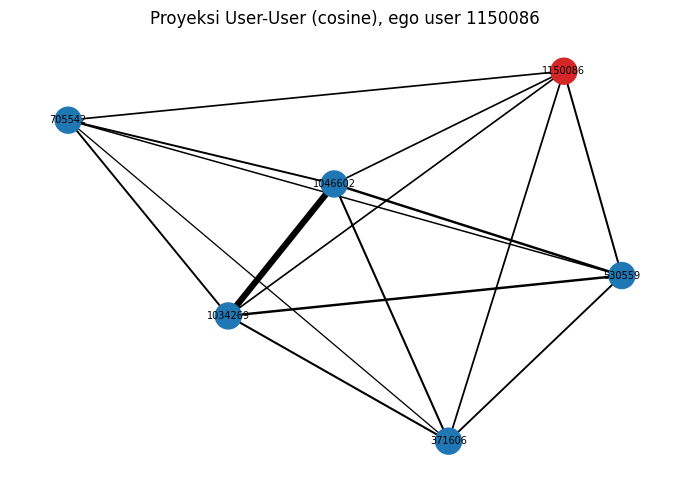

simpul: 6 | sisi: 15


In [34]:
def top_k_similar(Mn, idx, k):
    sims = (Mn[idx] @ Mn.T).toarray().ravel()
    sims[idx] = -1.0
    order = np.argsort(-sims, kind="stable")[:k]
    order = order[sims[order] > 0]
    return order, sims[order]

def plot_ego(Mn, ids, idx, k, title):
    nbr, _ = top_k_similar(Mn, idx, k)
    nodes = [idx] + list(nbr)
    sub = Mn[nodes]
    S = (sub @ sub.T).toarray()
    G = nx.Graph()
    G.add_nodes_from(str(ids[i]) for i in nodes)
    for a in range(len(nodes)):
        for b in range(a + 1, len(nodes)):
            if S[a, b] > 0:
                G.add_edge(str(ids[nodes[a]]), str(ids[nodes[b]]), weight=float(S[a, b]))
    pos = nx.spring_layout(G, seed=seed, weight="weight")
    colors = ["tab:red" if n == str(ids[idx]) else "tab:blue" for n in G.nodes]
    widths = [0.5 + 4 * G[u][v]["weight"] for u, v in G.edges]
    plt.figure(figsize=(7, 5))
    nx.draw_networkx(G, pos, node_color=colors, width=widths, node_size=350, font_size=7)
    plt.title(title); plt.axis("off"); plt.tight_layout(); plt.show()
    return G

ref_user_idx = int(np.argmax(np.diff(X.indptr)))      # user paling aktif
G_user = plot_ego(Xn, user_ids, ref_user_idx, 5,
                  f"Proyeksi User-User (cosine), ego user {user_ids[ref_user_idx]}")
print("simpul:", G_user.number_of_nodes(), "| sisi:", G_user.number_of_edges())

Ego graph terdiri dari user acuan, hingga lima tetangga dengan cosine positif tertinggi, dan hubungan di antara simpul tersebut. User acuan dipilih berdasarkan jumlah item berbeda terbanyak pada P1. Sisi yang lebih tebal menunjukkan cosine yang lebih besar. ID acuan, jumlah simpul, jumlah sisi, dan pola kelompok mengikuti output graf pada periode baru; graf ini merupakan sampel, bukan seluruh proyeksi User–User.

## No. 5: Vector Space Model (VSM) Item

Bagian ini menjelaskan Item sebagai vektor dengan dimensi user. VSM Item diperoleh dari transpose matriks User × Item (Xᵀ), sehingga bobot interaksinya sama dengan nomor 4 (VIEWED: 1, ADDED_TO_CART: 2, BOUGHT: 3), dijumlahkan bila berulang. Matriks kemudian dinormalisasi (L2) agar perkalian titik (dot product) antar-vektor sama dengan cosine similarity.

In [35]:
XT  = X.T.tocsr()                                 
XTn = normalize(XT, norm="l2", axis=1)
print("VSM Item (matriks Item x User):", XT.shape, "| nnz =", f"{XT.nnz:,}")

karakter_item = pd.DataFrame([describe_matrix(XT, "Item", "item", "user")]).set_index("VSM").T
display(karakter_item)

karakter = pd.DataFrame([
    describe_matrix(X,  "User", "user", "item"),
    describe_matrix(XT, "Item", "item", "user"),
]).set_index("VSM").T
print("\nPerbandingan karakteristik VSM User vs VSM Item:")
display(karakter)

VSM Item (matriks Item x User): (189066, 858124) | nnz = 1,285,103


VSM,Item
baris =,item
dimensi (kolom) =,user
shape,"(189066, 858124)"
nnz,1285103
densitas (%),0.000792
sparsitas (%),99.999208
nnz/baris min,1
median,2.0
mean,6.797113
max,1884



Perbandingan karakteristik VSM User vs VSM Item:


VSM,User,Item
baris =,user,item
dimensi (kolom) =,item,user
shape,"(858124, 189066)","(189066, 858124)"
nnz,1285103,1285103
densitas (%),0.000792,0.000792
sparsitas (%),99.999208,99.999208
nnz/baris min,1,1
median,1.0,2.0
mean,1.497573,6.797113
max,3328,1884


VSM Item merupakan transpose VSM User: baris mewakili item dan kolom mewakili user. Karena berasal dari matriks yang sama, nnz, densitas, dan sparsitas keseluruhannya tetap sama. Perbedaannya terletak pada jumlah baris, dimensi vektor, serta distribusi jumlah user per item. Nilai minimum, median, rata-rata, maksimum, dan persentase baris dengan satu elemen bukan nol ditampilkan dalam tabel.

### Ego graph proyeksi Item-Item

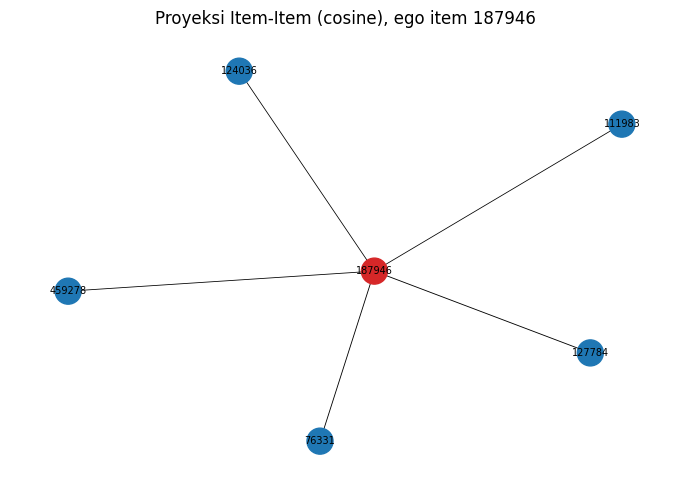

simpul: 6 | sisi: 5


In [36]:
ref_item_idx = int(np.argmax(np.diff(XT.indptr)))      
G_item = plot_ego(XTn, item_ids, ref_item_idx, 5,
                  f"Proyeksi Item-Item (cosine), ego item {item_ids[ref_item_idx]}")
print("simpul:", G_item.number_of_nodes(), "| sisi:", G_item.number_of_edges())

Ego graph Item–Item menggunakan item dengan jumlah user berbeda terbanyak sebagai acuan. Hingga lima item dengan cosine positif tertinggi ditampilkan bersama hubungan antar-item dalam sampel. Dua item memiliki cosine positif ketika ada user yang berinteraksi dengan keduanya. Ketebalan sisi mengikuti nilai cosine. Interpretasi jumlah simpul, sisi, dan kelompok didasarkan pada graf hasil periode baru.

## No. 6: Proyeksi mana yang lebih baik? 

Dua proyeksi dibandingkan berdasarkan jumlah simpul, dimensi vektor, batas atas sisi proyeksi, sparsitas, dan waktu pencarian top-k. Karakteristik ini menjelaskan biaya komputasi dan distribusi interaksi; efektivitas rekomendasi tidak dapat disimpulkan hanya dari kepadatan vektor.

In [37]:
du = np.diff(X.indptr).astype(np.int64)   
di = np.diff(XT.indptr).astype(np.int64)    

def proj_stats(n_nodes, deg_other):
    ub = int((deg_other * (deg_other - 1) // 2).sum())
    return ub, n_nodes * (n_nodes - 1) // 2

ub_u, mx_u = proj_stats(len(user_ids), di)
ub_i, mx_i = proj_stats(len(item_ids), du)

def avg_time(Mn, n=20):
    rng = np.random.default_rng(seed)
    idxs = rng.integers(0, Mn.shape[0], size=n)
    t0 = time.perf_counter()
    for i in idxs:
        top_k_similar(Mn, int(i), k_neighbors)
    return (time.perf_counter() - t0) / n * 1000

banding = pd.DataFrame({
    "simpul": [len(user_ids), len(item_ids)],
    "dimensi vektor": [len(item_ids), len(user_ids)],
    "batas atas sisi proyeksi": [ub_u, ub_i],
    "sisi maks. (graf lengkap)": [mx_u, mx_i],
    "rasio batas atas / maks": [ub_u / mx_u, ub_i / mx_i],
    "sparsitas VSM (%)": [100 * (1 - X.nnz / np.prod(X.shape))] * 2,
    "baris dengan 1 nnz (%)": [100 * float((du == 1).mean()), 100 * float((di == 1).mean())],
    "waktu 1 pencarian top-k (ms)": [avg_time(Xn), avg_time(XTn)],
}, index=["Proyeksi User-User", "Proyeksi Item-Item"])
display(banding)

,simpul,dimensi vektor,batas atas sisi proyeksi,sisi maks. (graf lengkap),rasio batas atas / maks,sparsitas VSM (%),baris dengan 1 nnz (%),waktu 1 pencarian top-k (ms)
Proyeksi User-User,858124,189066,36894934,368187970626,0.000100,99.999208,80.529387,42.738945
Proyeksi Item-Item,189066,858124,19935339,17872881645,0.001115,99.999208,38.670623,47.359215


In [38]:
U, I = banding.loc["Proyeksi User-User"], banding.loc["Proyeksi Item-Item"]
lebih_hemat = "User-User" if U["batas atas sisi proyeksi"] <= I["batas atas sisi proyeksi"] else "Item-Item"
lebih_cepat = "User-User" if U["waktu 1 pencarian top-k (ms)"] <= I["waktu 1 pencarian top-k (ms)"] else "Item-Item"

print('Proyeksi lebih hemat:', lebih_hemat)
print("Proyeksi lebih cepat:", lebih_cepat)

Proyeksi lebih hemat: Item-Item
Proyeksi lebih cepat: User-User


Tabel `banding` dan keluaran `lebih_hemat` serta `lebih_cepat` menjadi dasar pembahasan proyeksi untuk periode baru. Nilai batas atas sisi dihitung dari kombinasi pasangan melalui simpul perantara; satu pasangan dapat terhitung berulang, sehingga nilainya bukan jumlah sisi aktual. Waktu pencarian juga bergantung pada perangkat. Jangan menggunakan kesimpulan dan angka periode lama untuk periode ini. Bagian similarity berikut tetap mengikuti rancangan notebook, yaitu proyeksi User–User, yang juga digunakan oleh KNN pada bagian Analytics.

## No. 7: Similarity

In [39]:
REF_USER_SIM = user_ids[ref_user_idx]
nbr, sc = top_k_similar(Xn, ref_user_idx, 5)
sim_df = pd.DataFrame({"User": user_ids[nbr], "cosine": sc})
print("User acuan:", REF_USER_SIM)
display(sim_df)

q_write_sim = """
UNWIND $rows AS row
MATCH (a:User {visitorId: row.src})
MATCH (b:User {visitorId: row.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
rows = [{"src": str(REF_USER_SIM), "dst": str(u), "score": float(s)}
        for u, s in zip(sim_df["User"], sim_df["cosine"])]
with driver.session(database=uts) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s").consume()   
    write_tx(session, lambda tx: tx.run(q_write_sim, rows=rows).consume())
print(f"{len(rows)} relasi SIMILAR_TO ditulis ke graf.")


q_top5 = """
MATCH (r:User {visitorId: $ref})-[s:SIMILAR_TO]->(n:User)
RETURN n.visitorId AS User, s.score AS cosine
ORDER BY s.score DESC, n.visitorId ASC
LIMIT 5
"""
dari_graf = pd.DataFrame(run_query(q_top5, ref=str(REF_USER_SIM)))
identik = (set(dari_graf["User"]) == set(sim_df["User"])
           and np.allclose(np.sort(dari_graf["cosine"]), np.sort(sim_df["cosine"])))
print("Hasil yang dibaca kembali dari graf identik dengan hasil Python:", identik)

User acuan: 1150086


,User,cosine
0,530559,0.234013
1,371606,0.196128
2,705542,0.180167
3,1034269,0.178341
4,1046602,0.178341


5 relasi SIMILAR_TO ditulis ke graf.
Hasil yang dibaca kembali dari graf identik dengan hasil Python: True


**a.**
Cosine similarity dihitung pada VSM User yang telah dinormalisasi L2 (`Xn`). User acuan adalah user teraktif yang dipilih sebelumnya. Fungsi `top_k_similar()` mengambil hingga lima user lain dengan cosine positif tertinggi. ID dan nilai similarity dibaca dari tabel `sim_df` setelah notebook dijalankan.

Query Cypher top-5 pada `q_top5`:
```cypher
MATCH (r:User {visitorId: $ref})-[s:SIMILAR_TO]->(n:User)
RETURN n.visitorId AS User, s.score AS cosine
ORDER BY s.score DESC, n.visitorId ASC
LIMIT 5
```

**b.**
Nilai similarity disimpan sebagai relasi `SIMILAR_TO`; properti `score` berisi cosine dan `metric` berisi nama metrik.
```cypher
UNWIND $rows AS row
MATCH (a:User {visitorId: row.src})
MATCH (b:User {visitorId: row.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
```

Jumlah relasi yang ditulis serta hasil pemeriksaan pembacaan kembali mengikuti output kode di atas.

## No. 8: Kondisi graf sebelum dan sesudah similarity

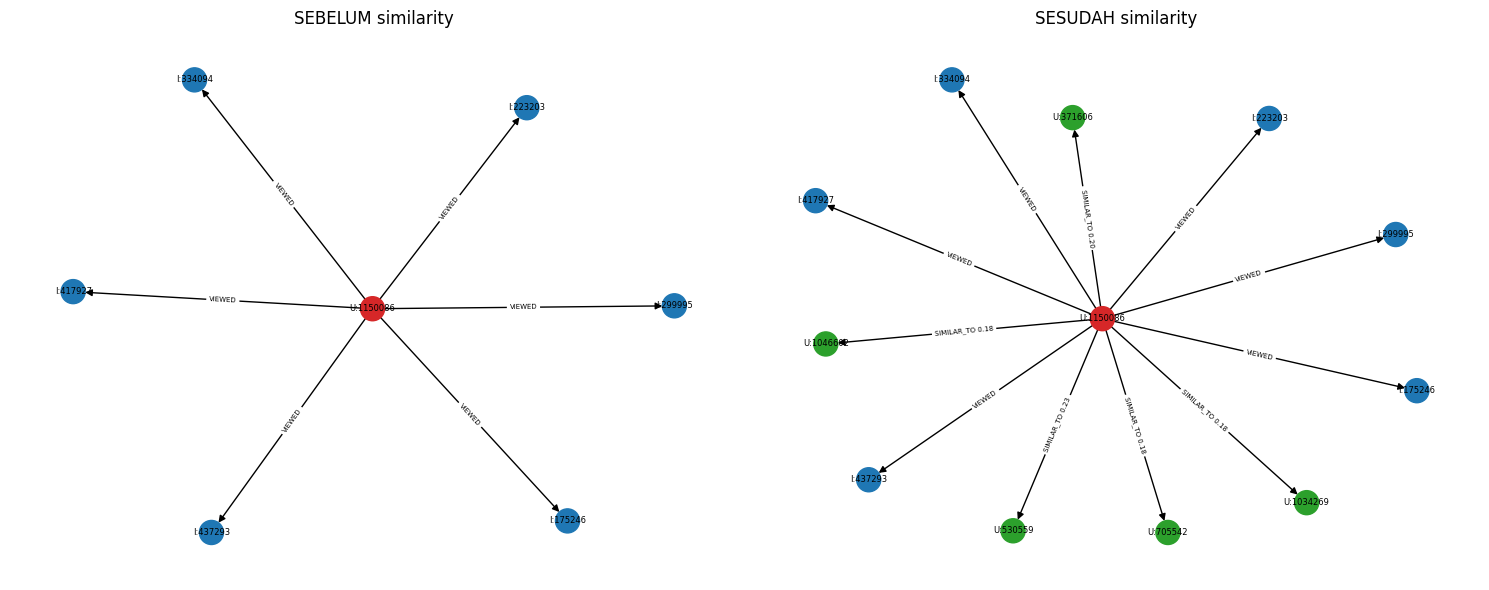

In [41]:
q_before = """
MATCH (u:User {visitorId: $u})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN i.itemId AS item, type(r) AS rel LIMIT 7
"""
before = pd.DataFrame(run_query(q_before, u=str(REF_USER_SIM)))
after_sim = pd.DataFrame(run_query(q_top5, ref=str(REF_USER_SIM)))

def build_graph(with_sim):
    G = nx.DiGraph()
    u = f"U:{REF_USER_SIM}"
    for _, r in before.iterrows():
        G.add_edge(u, f"I:{r['item']}", rel=r["rel"])
    if with_sim:
        for _, r in after_sim.iterrows():
            G.add_edge(u, f"U:{r['User']}", rel=f"SIMILAR_TO {r['cosine']:.2f}")
    return G

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, flag, ttl in zip(axes, [False, True], ["SEBELUM similarity", "SESUDAH similarity"]):
    G = build_graph(flag)
    pos = nx.spring_layout(G, seed=seed)
    cols = ["tab:red" if n == f"U:{REF_USER_SIM}" else ("tab:green" if n.startswith("U:") else "tab:blue") for n in G.nodes]
    nx.draw_networkx(G, pos, ax=ax, node_color=cols, node_size=300, font_size=6, arrows=True)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=nx.get_edge_attributes(G, "rel"), font_size=5)
    ax.set_title(ttl); ax.axis("off")
plt.tight_layout(); plt.show()

In [42]:
rel_counts_after = pd.DataFrame(run_query(q_rels))
perbandingan = pd.concat([
    rel_counts_before.set_index("jenis_relasi")["jumlah"].rename("sebelum"),
    rel_counts_after.set_index("jenis_relasi")["jumlah"].rename("sesudah"),
], axis=1).fillna(0).astype(int)
perbandingan

,sebelum,sesudah
jenis_relasi,,
VIEWED,1590454,1590454
ADDED_TO_CART,41599,41599
BOUGHT,13558,13558
SIMILAR_TO,0,5


Panel sebelum menampilkan sampel relasi interaksi user acuan ke item. Panel sesudah menambahkan relasi SIMILAR_TO menuju user lain. Tabel `perbandingan` menunjukkan jumlah relasi sebelum dan sesudah penulisan similarity.

Untuk menampilkan graf di Neo4j Browser, isi parameter `$ref` dengan ID user acuan pada output nomor 7, sebagai string sesuai tipe ID di notebook.

Sebelum:
```cypher
MATCH p = (u:User {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
RETURN p LIMIT 7
```

Sesudah:
```cypher
MATCH p = (u:User {visitorId: $ref})-[:SIMILAR_TO]->(:User)
RETURN p
```

Jumlah relasi interaksi seharusnya tetap, sedangkan relasi SIMILAR_TO bertambah sesuai tetangga yang disimpan. Interpretasi angka mengikuti output periode baru.

# 2.2 Analytics (training = P1, testing = P2)

Pada bagian ini data P1 dipakai sebagai data training, yaitu matriks User x Item (X) yang sudah dibentuk pada nomor 4. Data P2 dipakai sebagai ground truth, yaitu item yang benar-benar diakses user setelah periode P1. Karena item yang sudah diakses di P1 tidak direkomendasikan lagi, item relevan yang dipakai adalah item P2 yang belum pernah diakses user tersebut di P1 (disebut truth_new).

In [43]:
p2_test = pd.read_csv(P2_CSV, dtype=str)
p2_test = p2_test[p2_test["event"].isin(relevan_events)]
truth = p2_test.groupby("visitorid")["itemid"].apply(set).to_dict()

user_p1_p2 = [u for u in user_ids if u in truth]
truth_new = {}
for u in user_p1_p2:
    item_p1 = set(item_ids[X[user_pos[u]].indices])
    truth_new[u] = truth[u] - item_p1
kandidat = []
for u in user_p1_p2:
    if X[user_pos[u]].nnz >= min_p1_items and len(truth_new[u]) > 0:
        kandidat.append(u)
kandidat.sort()

print("user di P1 dan P2 :", len(user_p1_p2))
print("jumlah kandidat   :", len(kandidat))

user di P1 dan P2 : 17284
jumlah kandidat   : 6222


## No. 1: KNN

### a.
Rekomendasi dibuat dengan KNN berbasis user. Pertama dicari k = 5 user dengan cosine similarity tertinggi terhadap user target. Kedua, skor setiap item dihitung dengan menjumlahkan hasil kali cosine tetangga dengan bobot interaksi tetangga pada item tersebut. Ketiga, item yang sudah pernah diakses user target di P1 dibuang. Keempat, item diurutkan dari skor terbesar dan lima teratas diambil.

User dipilih secara acak dari daftar kandidat. Daftar kandidat diurutkan lebih dulu, kemudian `np.random.default_rng(seed)` dipakai untuk memilih satu posisi, sehingga hasilnya sama setiap kali kode dijalankan. Selain punya minimal dua item di P1 dan minimal satu item baru di P2, kandidat juga harus menghasilkan minimal tiga rekomendasi dari KNN, supaya tiga item iklan benar-benar berasal dari KNN.

In [44]:
def rekomendasi_knn(idx, k=k_neighbors, n=n_rec):
    tetangga, sim = top_k_similar(Xn, idx, k)
    skor = np.asarray(X[tetangga].T @ sim).ravel()
    skor[X[idx].indices] = 0           
    urut = np.argsort(-skor, kind="stable")[:n]
    urut = urut[skor[urut] > 0]
    return urut, skor[urut], tetangga, sim

kandidat_knn = []
for u in kandidat:
    hasil = rekomendasi_knn(user_pos[u])
    if len(hasil[0]) >= n_ads:
        kandidat_knn.append(u)
print("kandidat dengan KNN >=", n_ads, "item:", len(kandidat_knn), "dari", len(kandidat))

rng = np.random.default_rng(seed)
user_acak = kandidat_knn[rng.integers(len(kandidat_knn))]
idx = user_pos[user_acak]
print("user terpilih:", user_acak, "| seed:", seed)
print("item di P1:", X[idx].nnz, "| item baru di P2:", len(truth_new[user_acak]))

kandidat dengan KNN >= 3 item: 878 dari 6222
user terpilih: 1126031 | seed: 42
item di P1: 5 | item baru di P2: 1


Jumlah user yang muncul pada P1 dan P2, kandidat yang memenuhi syarat, serta kandidat dengan minimal tiga rekomendasi ditampilkan oleh kode. Satu user dipilih dari daftar kandidat yang sudah diurutkan menggunakan `np.random.default_rng(42)`. ID terpilih dan jumlah itemnya mengikuti output periode baru.

Pemilihan ini mengikuti notebook asli: populasi dibatasi pada user yang memiliki interaksi baru di P2 dan memenuhi syarat rekomendasi. Dengan demikian, hasil merupakan evaluasi pada kelompok tersebut, bukan sampel seluruh user P1; P2 dipakai untuk menentukan kelayakan evaluasi, sedangkan bobot, similarity, dan skor rekomendasi tetap berasal dari P1.

### b. 



In [46]:
item_rek, skor_rek, tetangga, sim = rekomendasi_knn(idx)

tabel_tetangga = pd.DataFrame({"tetangga": user_ids[tetangga], "cosine": sim})
print("lima tetangga terdekat user", user_acak)
display(tabel_tetangga)

tabel_rek = pd.DataFrame({"peringkat": range(1, len(item_rek) + 1),
                          "item": item_ids[item_rek],
                          "skor": skor_rek})
print("rekomendasi teratas")
display(tabel_rek)

iklan = list(item_ids[item_rek[:n_ads]])
print("item yang diiklankan:", iklan)

lima tetangga terdekat user 1126031


,tetangga,cosine
0,1328447,0.707107
1,508061,0.707107
2,849681,0.707107
3,852154,0.500000
4,921539,0.408248


rekomendasi teratas


,peringkat,item,skor
0,1,3112,0.500000
1,2,249444,0.408248
2,3,27897,0.408248


item yang diiklankan: ['3112', '249444', '27897']


Tabel `tabel_tetangga` menampilkan hingga lima tetangga dengan cosine positif tertinggi untuk user terpilih. Tabel `tabel_rek` menampilkan item yang belum diakses user pada P1, diurutkan berdasarkan skor KNN. Tiga item teratas menjadi item iklan. Jika skor sama, pengurutan stabil mengikuti urutan indeks item. ID tetangga, ID item, dan skor harus dibaca dari hasil eksekusi baru.

## No. 2: Hit@5 dan NDCG@5

### a. Hit@5
Hit@5 bernilai 1 bila ada minimal satu item relevan di antara lima item rekomendasi, dan bernilai 0 bila tidak ada. Item relevan adalah item yang diakses user di P2 tetapi belum pernah diakses di P1 (truth_new).

In [47]:
relevan = truth_new[user_acak]
rek = list(item_ids[item_rek])

tabel_hit = pd.DataFrame({"peringkat": range(1, len(rek) + 1),
                          "item": rek,
                          "relevan": [1 if i in relevan else 0 for i in rek]})
display(tabel_hit)
print("item relevan di P2:", sorted(relevan))

hit = 0
for i in rek[:n_rec]:
    if i in relevan:
        hit = 1
print("Hit@5 =", hit)

,peringkat,item,relevan
0,1,3112,0
1,2,249444,0
2,3,27897,0


item relevan di P2: ['269088']
Hit@5 = 0


Bandingkan lima rekomendasi dengan himpunan `truth_new` untuk user terpilih. Hit@5 bernilai 1 jika sedikitnya satu item rekomendasi relevan, dan 0 jika tidak ada. Nilai untuk periode baru mengikuti output kode, bukan hasil periode sebelumnya.

### b. NDCG@5

NDCG@5 memperhitungkan posisi item relevan. DCG dihitung dengan menjumlahkan 1 / log2(i + 1) untuk setiap item relevan di peringkat i. IDCG adalah DCG ideal, yaitu bila semua item relevan user (paling banyak 5) berada di peringkat teratas. NDCG@5 adalah DCG dibagi IDCG.

In [48]:
dcg = 0
for peringkat, i in enumerate(rek[:n_rec], start=1):
    if i in relevan:
        dcg += 1 / np.log2(peringkat + 1)

jumlah_ideal = min(len(relevan), n_rec)
idcg = 0
for peringkat in range(1, jumlah_ideal + 1):
    idcg += 1 / np.log2(peringkat + 1)

ndcg = dcg / idcg
print("DCG@5  =", round(dcg, 4))
print("IDCG@5 =", round(idcg, 4))
print("NDCG@5 =", round(ndcg, 4))

DCG@5  = 0
IDCG@5 = 1.0
NDCG@5 = 0.0


DCG@5 dihitung dari posisi item relevan pada daftar rekomendasi. IDCG@5 menggunakan jumlah seluruh item relevan user, paling banyak lima, dalam urutan ideal. Nilai NDCG@5 mengikuti hasil pembagian DCG@5 dengan IDCG@5 pada output. Kandidat user dalam notebook disyaratkan memiliki setidaknya satu item relevan baru di P2.

Hit@5 dan NDCG@5 pada satu user acak hanya menggambarkan hasil untuk user tersebut. Nilai nol berarti tidak ada item relevan pada lima rekomendasi, bukan otomatis berarti model gagal pada seluruh pengguna. Notebook ini tidak menghitung evaluasi seluruh populasi atau baseline popularitas, sehingga angka perbandingan tersebut tidak dicantumkan.

## Tutup koneksi

In [ ]:
driver.close()
print("Koneksi ditutup.")